# Radionica 2 — Prvi ML model: koliko vrijedi stan u Tuzli? 🏠

Na prvoj radionici smo **gledali** podatke. Danas ćemo pustiti računar da **uči** iz njih.

Plan:
1. Napravimo "model" bez ML-a — jedno pravilo koje smo sami smislili
2. Napravimo prvi pravi ML model (linearna regresija)
3. Dodajemo sve više informacija o stanovima
4. Isprobamo drugi model (random forest)
5. **Feature engineering** — sami smišljamo nove kolone
6. Leaderboard 🏆

Ćelije označene sa `# TODO` su vaše. Gdje vidite `___`, tu trebate nešto upisati.

## 0. Priprema
Pokrenite ćeliju ispod (Shift + Enter).

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

def rmse(stvarno, predvidjeno):
    """Prosječna greška u KM (kvadratna — velike greške se kažnjavaju više)."""
    return np.sqrt(np.mean((np.array(stvarno) - np.array(predvidjeno)) ** 2))

def mae(stvarno, predvidjeno):
    """Prosječna greška u KM (obična — koliko u prosjeku promašimo)."""
    return np.mean(np.abs(np.array(stvarno) - np.array(predvidjeno)))

print("Sve spremno ✅")

Sve spremno ✅


## 1. Podaci
Ovo je proširena verzija stanova iz prošle radionice — sada imamo i godinu izgradnje, sprat, lift, parking, opis oglasa...

In [7]:
df = pd.read_csv("stanovi_r2.csv")
print(df.shape)
df.head()


(2000, 14)


,id,naselje,kvadratura_m2,broj_soba,sprat,ukupno_spratova,godina_izgradnje,lift,parking,balkon,grijanje,stanje,opis,cijena_km
0,1,Brčanska Malta,103,5,2,4,1981,0,0,1,plin,renoviran,"5-soban stan, 103 m², Brčanska Malta. Kompletn...",316000
1,2,Kreka,99,4,7,7,2011,1,1,1,centralno,renoviran,"4-soban stan, 99 m², Kreka. Kompletno renoviran.",392000
2,3,Simin Han,46,2,0,5,1972,0,0,1,centralno,useljiv,"2-soban stan, 46 m², Simin Han. HITNO, cijena ...",123500
3,4,Stupine,40,2,2,5,1986,1,0,1,centralno,renoviran,"2-soban stan, 40 m², Stupine. Kompletno renovi...",186000
4,5,Slatina,48,3,6,8,1997,1,0,1,centralno,useljiv,"3-soban stan, 48 m², Slatina. Prelijep pogled ...",225500


In [8]:
df.describe()

,id,kvadratura_m2,broj_soba,sprat,ukupno_spratova,godina_izgradnje,lift,parking,balkon,cijena_km
count,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.00000,2000.00000,2000.000000
mean,1000.500000,63.830500,2.643500,3.515500,6.960000,1993.760500,0.723500,0.38350,0.68700,261547.750000
std,577.494589,22.920088,1.064882,2.706552,2.537641,19.891203,0.447379,0.48636,0.46383,111718.803881
min,1.000000,24.000000,1.000000,0.000000,3.000000,1961.000000,0.000000,0.00000,0.00000,74000.000000
25%,500.750000,47.000000,2.000000,1.000000,5.000000,1977.000000,0.000000,0.00000,0.00000,181500.000000
50%,1000.500000,60.000000,3.000000,3.000000,7.000000,1989.000000,1.000000,0.00000,1.00000,238750.000000
75%,1500.250000,76.000000,3.000000,5.000000,9.000000,2012.000000,1.000000,1.00000,1.00000,316000.000000
max,2000.000000,160.000000,5.000000,12.000000,12.000000,2026.000000,1.000000,1.00000,1.00000,935500.000000


## 2. "Model" bez ML-a: pravilo koje smo sami napisali

Najjednostavniji način da procijenimo cijenu stana:

> **cijena = kvadratura × 4160 KM**

Ovo je 🟢 *običan program* — mi smo napisali pravilo. Koliko je dobro?

In [9]:
df["pravilo"] = df["kvadratura_m2"] * 4160

print(f"MAE  (prosječna greška):        {mae(df['cijena_km'], df['pravilo']):,.0f} KM")
print(f"RMSE (kažnjava velike greške):  {rmse(df['cijena_km'], df['pravilo']):,.0f} KM")

MAE  (prosječna greška):        55,413 KM
RMSE (kažnjava velike greške):  74,603 KM


**MAE** = u prosjeku promašimo za toliko KM.
**RMSE** = slično, ali velike greške boli više. Danas koristimo RMSE za leaderboard — **manje je bolje**.

In [11]:
# TODO: Probajte neki drugi broj umjesto 4160. Možete li smanjiti grešku?
cijena_po_m2 = 3500

df["pravilo"] = df["kvadratura_m2"] * cijena_po_m2
print(f"RMSE: {rmse(df['cijena_km'], df['pravilo']):,.0f} KM")

RMSE: 83,007 KM


💬 Šta mislite — da li postoji *jedan* broj koji dobro radi za stan u Centru i stan u Gornjoj Tuzli?

## 3. Sakrijemo dio stanova (train / test)

Model uči na **80%** stanova (*train*), a provjeravamo ga na **20%** koje nikad nije vidio (*test*).

Kao ispit: ako ste vidjeli tačna pitanja unaprijed, odličan rezultat ne znači da znate gradivo. 📚

In [12]:
y = df["cijena_km"]   # ono što predviđamo (target)

train_idx, test_idx = train_test_split(df.index, test_size=0.2, random_state=42)
print(f"Train: {len(train_idx)} stanova  |  Test: {len(test_idx)} stanova")

# Koliko je dobro naše pravilo na TEST stanovima?
rmse_pravilo = rmse(y[test_idx], df.loc[test_idx, "kvadratura_m2"] * 4160)
print(f"Pravilo na test skupu: RMSE = {rmse_pravilo:,.0f} KM")

Train: 1600 stanova  |  Test: 400 stanova
Pravilo na test skupu: RMSE = 76,415 KM


## 4. Prvi ML model 🔵 — linearna regresija

Ista ideja kao pravilo, ali **računar sam pronalazi brojeve**.

Svaki model u scikit-learn radi isto:
- `model.fit(X, y)` → uči
- `model.predict(X)` → predviđa

In [13]:
X = df[["kvadratura_m2"]]

model = LinearRegression()
model.fit(X.loc[train_idx], y[train_idx])          # učenje
predikcije = model.predict(X.loc[test_idx])         # predviđanje

print(f"Model je sam naučio: cijena ≈ {model.coef_[0]:,.0f} KM × m² + {model.intercept_:,.0f} KM")
print(f"RMSE na test skupu: {rmse(y[test_idx], predikcije):,.0f} KM")

Model je sam naučio: cijena ≈ 3,689 KM × m² + 25,427 KM
RMSE na test skupu: 75,370 KM


Pogledajmo obje linije na grafikonu. Svaka tačka je jedan stan iz train skupa.
Isprekidane vertikalne crte su **greške** — model bira liniju kod koje su te greške ukupno najmanje.

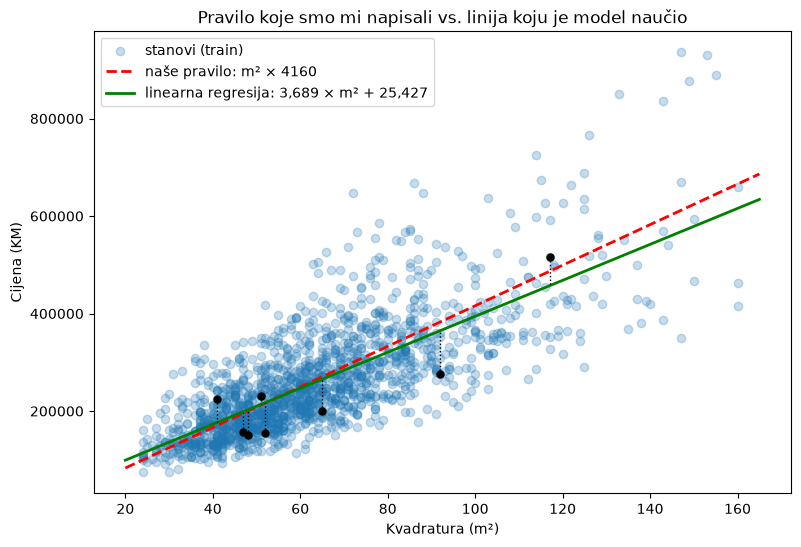

In [14]:
x = np.linspace(20, 165, 100)
plt.figure(figsize=(9, 6))
plt.scatter(df.loc[train_idx, "kvadratura_m2"], y[train_idx], alpha=0.25, label="stanovi (train)")
plt.plot(x, x * 4160, "r--", linewidth=2, label="naše pravilo: m² × 4160")
plt.plot(x, model.predict(pd.DataFrame({"kvadratura_m2": x})), "g-", linewidth=2,
         label=f"linearna regresija: {model.coef_[0]:,.0f} × m² + {model.intercept_:,.0f}")

# nekoliko grešaka (udaljenost tačke od zelene linije)
primjer = df.loc[train_idx].sample(8, random_state=1)
for _, r in primjer.iterrows():
    p = model.predict(pd.DataFrame({"kvadratura_m2": [r["kvadratura_m2"]]}))[0]
    plt.plot([r["kvadratura_m2"]] * 2, [r["cijena_km"], p], "k:", linewidth=1)
plt.scatter(primjer["kvadratura_m2"], primjer["cijena_km"], color="black", s=25, zorder=3)

plt.xlabel("Kvadratura (m²)")
plt.ylabel("Cijena (KM)")
plt.title("Pravilo koje smo mi napisali vs. linija koju je model naučio")
plt.legend()
plt.show()

💬 Linije su slične — zato model nije mnogo bolji od pravila. Ima premalo informacija: stan od 60 m² u Centru i u Gornjoj Tuzli za njega je isti. Hajde da mu damo više.

## 5. Pomoćna funkcija `isprobaj`

Da ne pišemo isti kod svaki put: dajete joj **model** i **listu kolona**, ona uči i vrati grešku na test skupu.

In [15]:
rezultati = []   # ovdje pamtimo sve pokušaje

def isprobaj(model, kolone, opis=""):
    X = pd.get_dummies(df[kolone], dtype=float)     # tekstualne kolone pretvara u brojeve
    model.fit(X.loc[train_idx], y[train_idx])
    pred = model.predict(X.loc[test_idx])
    greska = rmse(y[test_idx], pred)
    ime = type(model).__name__
    rezultati.append({"model": ime, "broj_kolona": len(kolone), "RMSE": round(greska), "opis": opis})
    print(f"{ime:25s} {len(kolone):2d} kolona  →  RMSE = {greska:,.0f} KM")
    return pred

isprobaj(LinearRegression(), ["kvadratura_m2"], "samo m²");

LinearRegression           1 kolona  →  RMSE = 75,370 KM


## 6. Više informacija → bolji model?

Dodajte brojčane kolone koje mislite da utiču na cijenu.
Dostupne: `kvadratura_m2`, `broj_soba`, `sprat`, `ukupno_spratova`, `godina_izgradnje`, `lift`, `parking`, `balkon`

In [16]:
# TODO: dopunite listu kolona
brojcane = ["kvadratura_m2", "godina_izgradnje", "sprat"]

pred = isprobaj(LinearRegression(), brojcane, "brojčane kolone")

LinearRegression           3 kolona  →  RMSE = 57,475 KM


Pogledajmo kako model griješi — svaka tačka je jedan stan. Što bliže crvenoj liniji, to bolje.

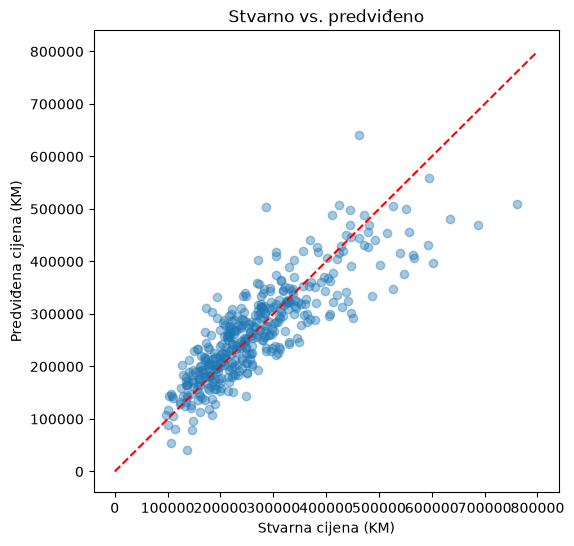

In [17]:
plt.figure(figsize=(6, 6))
plt.scatter(y[test_idx], pred, alpha=0.4)
plt.plot([0, 800000], [0, 800000], "r--")
plt.xlabel("Stvarna cijena (KM)")
plt.ylabel("Predviđena cijena (KM)")
plt.title("Stvarno vs. predviđeno")
plt.show()

---
# ☕ Pauza
---

## 7. Tekstualne kolone: naselje, grijanje, stanje

Model razumije samo brojeve. `pd.get_dummies` pretvara npr. `naselje` u više kolona sa 0/1 — po jednu za svako naselje:

In [18]:
pd.get_dummies(df[["naselje"]], dtype=int).head()

,naselje_Batva,naselje_Brčanska Malta,naselje_Centar,naselje_Gornja Tuzla,naselje_Kreka,naselje_Kula,naselje_Mejdan,naselje_Simin Han,naselje_Sjenjak,naselje_Slatina,naselje_Solana,naselje_Stupine
0,0,1,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,1,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,1,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,0,1
4,0,0,0,0,0,0,0,0,0,1,0,0


Funkcija `isprobaj` to već radi umjesto vas — samo dodajte kolone u listu.

In [19]:
# TODO: dopunite listu kolona
brojcane = ["kvadratura_m2", "godina_izgradnje", "sprat"]

pred = isprobaj(LinearRegression(), brojcane, "brojčane kolone")

LinearRegression           3 kolona  →  RMSE = 57,475 KM


## 8. Drugi model: Random Forest 🌳🌳🌳

Puno malih stabala odlučivanja. Svako postavlja pitanja tipa *"veći od 70 m²?"*, *"u Centru?"*, *"izgrađen poslije 2010?"* — i na kraju **glasaju**.

Isti `fit` / `predict`, samo drugi model.

In [22]:
# TODO: isprobajte RandomForestRegressor na istim kolonama kao gore
isprobaj(RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1), brojcane, "random forest");


RandomForestRegressor      3 kolona  →  RMSE = 53,439 KM


💬 Koji je bolji? Zašto mislite da je tako?

## 9. Feature engineering 🔧 — sami pravimo nove kolone

Sjetite se brainstorma: neke stvari nisu direktno u podacima, ali ih možemo **izvesti** iz postojećih kolona.

Primjer — starost zgrade:

In [21]:
df["starost"] = 2026 - df["godina_izgradnje"]
df[["godina_izgradnje", "starost"]].head()

,godina_izgradnje,starost
0,1981,45
1,2011,15
2,1972,54
3,1986,40
4,1997,29


Ideje za nove kolone (napravite bar 2–3):

| Nova kolona | Iz čega? | Zašto bi mogla pomoći? |
|---|---|---|
| `prizemlje` | `sprat == 0` | prizemlje je često jeftinije |
| `zadnji_sprat` | `sprat == ukupno_spratova` | krov, vrućina ljeti... |
| `visoko_bez_lifta` | sprat ≥ 4 **i** nema lift | ko nosi kese na 6. sprat? 😅 |
| `nova_gradnja` / `stara_gradnja` | `starost` | cijena ne raste ravnomjerno sa godinama |
| `hitno` | `opis` sadrži "HITNO" | prodavac žuri → niža cijena |

Savjet: `(uslov).astype(int)` pretvara True/False u 1/0.

In [23]:
# TODO: napravite nove kolone (dopunite uslove)
df["prizemlje"]        = (df["sprat"] == 0).astype(int)
df["visoko_bez_lifta"] = ((df["sprat"] >= 4) & (df["lift"] == 0)).astype(int)
df["hitno"]            = df["opis"].str.contains("HITNO", case=False, na=False).astype(int)

# Vaše ideje:
df["nova_gradnja"] = (df["godina_izgradnje"] >= 2010).astype(int)

df[["sprat", "lift", "prizemlje", "visoko_bez_lifta", "hitno", "nova_gradnja"]].head()

,sprat,lift,prizemlje,visoko_bez_lifta,hitno,nova_gradnja
0,2,0,0,0,0,0
1,7,1,0,0,0,1
2,0,0,1,0,1,0
3,2,1,0,0,0,0
4,6,1,0,0,0,0


In [27]:
# TODO: dodajte nove kolone u listu i isprobajte OBA modela
nove = ["prizemlje", "visoko_bez_lifta", "hitno", "nova_gradnja"]
sve_kolone = brojcane + nove

isprobaj(LinearRegression(), sve_kolone, "+ moje nove kolone")
isprobaj(RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1), sve_kolone, "+ moje nove kolone");

LinearRegression           7 kolona  →  RMSE = 52,376 KM
RandomForestRegressor      7 kolona  →  RMSE = 52,577 KM


⚠️ **Pažnja — varanje!** Da li bi kolona `cijena_po_m2 = cijena_km / kvadratura_m2` pomogla? Bi — ali ona već sadrži odgovor. 
U stvarnosti ne znamo cijenu stana koji tek procjenjujemo. To se zove **data leakage**.

## 10. Leaderboard 🏆

Svi vaši pokušaji, od najboljeg:

In [28]:
pd.DataFrame(rezultati).sort_values("RMSE").reset_index(drop=True)

,model,broj_kolona,RMSE,opis
0,LinearRegression,7,52376,+ moje nove kolone
1,RandomForestRegressor,7,52577,+ moje nove kolone
2,RandomForestRegressor,3,53439,random forest
3,LinearRegression,3,57475,brojčane kolone
4,LinearRegression,3,57475,brojčane kolone
5,LinearRegression,1,75370,samo m²


Upišite **najbolji RMSE** i **koje ste nove kolone napravile** u zajedničku tabelu.

Imate još vremena? Probajte:
- još neku novu kolonu (npr. iz `opis` — "pogled", "renoviran")
- izbaciti neku kolonu — da li model postaje gori ili bolji?
- `RandomForestRegressor(n_estimators=500, max_depth=10, ...)` — mijenjaju li postavke rezultat?

## 11. Zadaća 📝

Izaberite **jedno**:

1. **Pravi oglas:** nađite jedan stvarni oglas za stan u Tuzli (OLX), upišite njegove podatke i pogledajte koliko vaš model griješi. Da li je oglas "preskup" ili "povoljan"?
2. **Nova kolona:** smislite i napravite još jednu novu kolonu. Da li se RMSE smanjio? Napišite u 2–3 rečenice zašto mislite da jeste / nije.

Za opciju 1 možete koristiti ovaj kod:

Matplotlib is building the font cache; this may take a moment.


   m2  cijena
0  45  180000
1  60  240000
2  75  300000
3  90  370000


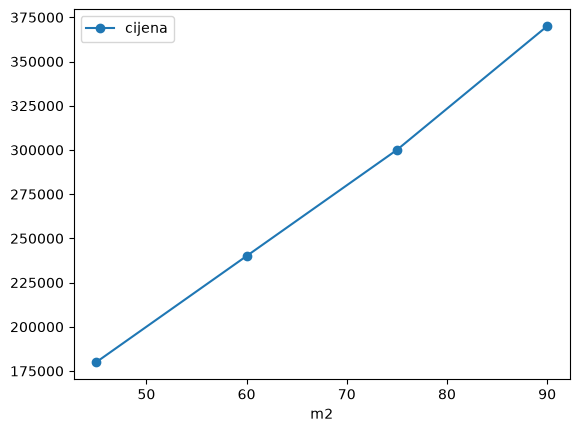

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.DataFrame({"m2": [45, 60, 75, 90], "cijena": [180000, 240000, 300000, 370000]})
print(df)
df.plot(x="m2", y="cijena", marker="o")
plt.show()